# 0. Imports

In [ ]:

from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

import xgboost as xgb
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder



pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:,.2f}'.format)


DATA_DIR = Path('.') / 'data'
PAX_TARGET = "OD_PAX_LOG"  
REV_TARGET = "OD_REV_USD_LOG"      
VAL_MONTHS = 12     


In [ ]:
def prepare_datasets(
    df: pd.DataFrame,
    target_col: str,
    val_months: int = 12,
    drop_covid_targets: bool = True,
):
    """
    Separates `full_spine` into leak-free train, validation, and 2027-2028 forecast sets.
    Automatically casts object/string features to `category` dtype for native tree support.
    """
    work_df = df.copy()

    # 1. Define columns that must NEVER enter X 
    non_feature_cols = {
        "ROUTE", "ORG_AIRPRT", "DES_AIRPRT", "DEP_YEAR", "DEP_MONTH",
        PAX_TARGET, REV_TARGET, "COVID",
    }
    feature_cols = [c for c in work_df.columns if c not in non_feature_cols]

    # 2. Cast remaining object/string columns to 'category'
    cat_cols = work_df[feature_cols].select_dtypes(include=["object", "string"]).columns.tolist()
    for col in cat_cols:
        work_df[col] = work_df[col].astype("category")

    # 3. Create helper chronological timestamp for exact time-based slicing
    work_df["_ts"] = pd.to_datetime(
        dict(year=work_df["DEP_YEAR"], month=work_df["DEP_MONTH"], day=1)
    )

    # Auto-detect exact historical cutoff T 
    cutoff_t = work_df.loc[work_df[target_col].notna(), "_ts"].max()
    val_start = cutoff_t - pd.DateOffset(months=val_months - 1)

    print(f"Historical Cutoff T: {cutoff_t.strftime('%Y-%m')}")
    print(f"Validation Window:   {val_start.strftime('%Y-%m')} -> {cutoff_t.strftime('%Y-%m')}")

    # 4. Filter valid historical rows 
    hist_mask = work_df[target_col].notna() & work_df[f"{target_col}_L24"].notna()
    if drop_covid_targets:
        hist_mask = hist_mask & (~work_df["DEP_YEAR"].isin([2020, 2021]))

    train_df = work_df[hist_mask & (work_df["_ts"] < val_start)].copy()
    val_df = work_df[hist_mask & (work_df["_ts"] >= val_start)].copy()
    forecast_df = work_df[work_df["_ts"] > cutoff_t].copy()

    return train_df, val_df, forecast_df, feature_cols, cat_cols


In [ ]:

# load metadata & feature lists
with open("./data/airline_metadata.json", "r", encoding="utf-8") as f:
    meta = json.load(f)

feature_cols = meta["feature_cols"]
cat_cols = meta["cat_cols"]
num_cols = meta["num_cols"]


# Load full_spine & recreate your train  val  forecast splits 
full_spine = pd.read_parquet("./data/full_spine_ready.parquet")
train_df, val_df, forecast_df, _, _ = prepare_datasets(
    df=full_spine,
    target_col="OD_PAX_LOG",
    val_months=12,
    drop_covid_targets=True,
)


print("All artifacts loaded cleanly!")


Historical Cutoff T: 2026-07
Validation Window:   2025-08 -> 2026-07
All artifacts loaded cleanly!


In [ ]:
def evaluate_predictions(y_true_log1p: pd.Series, y_pred_log1p: np.ndarray) -> dict:
    """Evaluates error in BOTH log1p space (model scale) and raw expm1 space (real units)."""
    y_pred_log1p = np.clip(y_pred_log1p, 0.0, None)

    y_true_raw = np.expm1(y_true_log1p)
    y_pred_raw = np.expm1(y_pred_log1p)

    return {
        "RMSE_log1p": round(root_mean_squared_error(y_true_log1p, y_pred_log1p), 4),
        "R2_log1p": round(r2_score(y_true_log1p, y_pred_log1p), 4),
        "MAE_raw": round(mean_absolute_error(y_true_raw, y_pred_raw), 2),
        "RMSE_raw": round(root_mean_squared_error(y_true_raw, y_pred_raw), 2),
    }


In [ ]:

def tune_target_ensemble(
    train_df: pd.DataFrame,
    val_df: pd.DataFrame,
    target_col: str,
    feature_cols: list,
    cat_cols: list,
    num_cols: list,
    n_iter_xgb: int = 15,
    n_iter_rf: int = 10,
):
    """Tunes XGBoost & RandomForest via TimeSeriesSplit for a single target and finds optimal blend weight."""
    print(f"\n{'='*60}\nTUNING ENSEMBLE FOR TARGET: {target_col}\n{'='*60}")

    # Sort chronologically so TimeSeriesSplit never leaks future months
    train_sorted = train_df.sort_values("_ts").reset_index(drop=True)
    X_tr, y_tr = train_sorted[feature_cols], train_sorted[target_col]
    X_val, y_val = val_df[feature_cols], val_df[target_col]

    tscv = TimeSeriesSplit(n_splits=3)

    # 1. Tune XGBoost
    xgb_base = xgb.XGBRegressor(
        tree_method="hist",
        enable_categorical=True,
        random_state=42,
        n_jobs=-1,
    )
    xgb_param_dist = {
        "n_estimators": (400, 700, 1000),
        "learning_rate": (0.02, 0.03, 0.05),
        "max_depth": (5, 7, 9),
        "min_child_weight": (5, 15, 30),
        "subsample": (0.7, 0.85, 1.0),
        "colsample_bytree": (0.6, 0.8, 1.0),
        "reg_alpha": (0.0, 0.5, 2.0),
        "reg_lambda": (1.0, 5.0, 10.0),
    }
    xgb_search = RandomizedSearchCV(
        estimator=xgb_base,
        param_distributions=xgb_param_dist,
        n_iter=n_iter_xgb,
        scoring="neg_root_mean_squared_error",
        cv=tscv,
        verbose=1,
        random_state=42,
        n_jobs=1,
    )
    xgb_search.fit(X_tr, y_tr)
    best_xgb = xgb_search.best_estimator_
    print(f"[{target_col}] Best XGB Params:", xgb_search.best_params_)

    # 2. Tune Random Forest
    rf_preprocessor = ColumnTransformer(
        transformers=[
            ("num", SimpleImputer(strategy="constant", fill_value=-999.0), num_cols),
            ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, encoded_missing_value=-2), cat_cols),
        ]
    )
    rf_pipe = Pipeline([
        ("prep", rf_preprocessor),
        ("rf", RandomForestRegressor(random_state=42, n_jobs=-1)),
    ])
    rf_param_dist = {
        "rf__n_estimators": (100, 150, 200),
        "rf__max_depth": (12, 16, 20),
        "rf__min_samples_leaf": (5, 10, 25),    
        "rf__max_features": (0.5, 0.7, "sqrt"),
        "rf__max_samples": (0.5, 0.75),
    }
    rf_search = RandomizedSearchCV(
        estimator=rf_pipe,
        param_distributions=rf_param_dist,
        n_iter=n_iter_rf,
        scoring="neg_root_mean_squared_error",
        cv=tscv,
        verbose=1,
        random_state=42,
        n_jobs=1,
    )
    rf_search.fit(X_tr, y_tr)
    best_rf = rf_search.best_estimator_
    print(f"[{target_col}] Best RF Params:", rf_search.best_params_)

    # Optimize Ensemble Blend Weight on Holdout Validation Year
    xgb_val_pred = best_xgb.predict(X_val)
    rf_val_pred = best_rf.predict(X_val)

    best_w, best_rmse = 0.5, float("inf")
    for w in [0.0, 0.3, 0.4, 0.5, 0.6, 0.7, 1.0]:
        blend = w * xgb_val_pred + (1 - w) * rf_val_pred
        score = evaluate_predictions(y_val, blend)["RMSE_log1p"]
        if score < best_rmse:
            best_rmse, best_w = score, w

    print(f"[{target_col}] Best Blend: {best_w:.1f} XGB + {1-best_w:.1f} RF | Val RMSE_log1p: {best_rmse}")

    return {
        "xgb_model": best_xgb,
        "rf_model": best_rf,
        "xgb_params": xgb_search.best_params_,
        "rf_params": rf_search.best_params_,
        "best_xgb_weight": best_w,
        "val_metrics": evaluate_predictions(y_val, best_w * xgb_val_pred + (1 - best_w) * rf_val_pred),
    }


# PAX
pax_results = tune_target_ensemble(
    train_df=train_df,
    val_df=val_df,
    target_col=PAX_TARGET,
    feature_cols=feature_cols,
    cat_cols=cat_cols,
    num_cols=num_cols,
)

for split_df in [train_df, val_df, forecast_df]:
    w_p = pax_results["best_xgb_weight"]
    split_df["Pred_Passengers_log1p"] = (
        w_p * pax_results["xgb_model"].predict(split_df[feature_cols])
        + (1 - w_p) * pax_results["rf_model"].predict(split_df[feature_cols])
    )

rev_feature_cols = feature_cols + ["Pred_Passengers_log1p"]
rev_num_cols = num_cols + ["Pred_Passengers_log1p"]

# REV
rev_results = tune_target_ensemble(
    train_df=train_df,
    val_df=val_df,
    target_col=REV_TARGET,
    feature_cols=rev_feature_cols,
    cat_cols=cat_cols,
    num_cols=rev_num_cols,
)



TUNING ENSEMBLE FOR TARGET: OD_PAX_LOG
Fitting 3 folds for each of 15 candidates, totalling 45 fits
[OD_PAX_LOG] Best XGB Params: {'subsample': 0.7, 'reg_lambda': 10.0, 'reg_alpha': 0.5, 'n_estimators': 700, 'min_child_weight': 5, 'max_depth': 9, 'learning_rate': 0.03, 'colsample_bytree': 0.8}
Fitting 3 folds for each of 10 candidates, totalling 30 fits
[OD_PAX_LOG] Best RF Params: {'rf__n_estimators': 100, 'rf__min_samples_leaf': 5, 'rf__max_samples': 0.5, 'rf__max_features': 'sqrt', 'rf__max_depth': 20}
[OD_PAX_LOG] Best Blend: 0.6 XGB + 0.4 RF | Val RMSE_log1p: 0.504

TUNING ENSEMBLE FOR TARGET: OD_REV_USD_LOG
Fitting 3 folds for each of 15 candidates, totalling 45 fits
[OD_REV_USD_LOG] Best XGB Params: {'subsample': 0.85, 'reg_lambda': 10.0, 'reg_alpha': 0.5, 'n_estimators': 1000, 'min_child_weight': 30, 'max_depth': 7, 'learning_rate': 0.03, 'colsample_bytree': 1.0}
Fitting 3 folds for each of 10 candidates, totalling 30 fits
[OD_REV_USD_LOG] Best RF Params: {'rf__n_estimators': 

In [ ]:
def build_and_fit_ensemble(
    full_train_df: pd.DataFrame,
    target_col: str,
    feature_cols: list,
    cat_cols: list,
    num_cols: list,
    xgb_params: dict,
    rf_params: dict,
):
    """
    Instantiates XGBoost and the Random Forest Pipeline using the winning hyperparameter
    dictionaries from `tune_target_ensemble()`, and fits both on `full_train_df`.
    """
    X_full = full_train_df[feature_cols]
    y_full = full_train_df[target_col]

    # 1. Build & fit tuned XGBoost
    final_xgb = xgb.XGBRegressor(
        tree_method="hist",
        enable_categorical=True,
        random_state=42,
        n_jobs=-1,
        **xgb_params,
    )
    final_xgb.fit(X_full, y_full)

    # 2. Build & fit tuned Random Forest Pipeline
    clean_rf_params = {
        k.replace("rf__", "", 1): v for k, v in rf_params.items()
    }

    rf_preprocessor = ColumnTransformer(
        transformers=[
            ("num", SimpleImputer(strategy="constant", fill_value=-999.0), num_cols),
            (
                "cat",
                OrdinalEncoder(
                    handle_unknown="use_encoded_value",
                    unknown_value=-1,
                    encoded_missing_value=-2,
                ),
                cat_cols,
            ),
        ]
    )

    final_rf = Pipeline([
        ("prep", rf_preprocessor),
        ("rf", RandomForestRegressor(random_state=42, n_jobs=-1, **clean_rf_params)),
    ])
    final_rf.fit(X_full, y_full)

    return final_xgb, final_rf


In [10]:
def predict_ensemble(
    df: pd.DataFrame,
    feature_cols: list,
    xgb_model,
    rf_model,
    xgb_weight: float,
) -> tuple[np.ndarray, np.ndarray]:
    """
    Computes weighted ensemble predictions in log1p space and converts back to raw units (expm1).
    """
    X = df[feature_cols]
    pred_log1p = (xgb_weight * xgb_model.predict(X)) + ((1.0 - xgb_weight) * rf_model.predict(X))
    pred_log1p = np.clip(pred_log1p, 0.0, None)
    pred_raw = np.expm1(pred_log1p)
    return pred_log1p, pred_raw


In [ ]:
#
# 1. Combine train and val so the model learns from validation set too (this is only for future forecasting not for model evaluating)
all_clean_hist = pd.concat([train_df, val_df], ignore_index=True)
forecast_out = forecast_df[["ROUTE", "ORG_AIRPRT", "DES_AIRPRT", "DEP_YEAR", "DEP_MONTH"]].copy()


# 2. Fit and predict PAX
print("Fitting final Passengers ensemble on all historical data...")
final_xgb_pax, final_rf_pax = build_and_fit_ensemble(
    full_train_df=all_clean_hist,
    target_col=PAX_TARGET,
    feature_cols=feature_cols,
    cat_cols=cat_cols,
    num_cols=num_cols,
    xgb_params=pax_results["xgb_params"],
    rf_params=pax_results["rf_params"],
)

all_clean_hist["Pred_Passengers_log1p"], _ = predict_ensemble(
    df=all_clean_hist,
    feature_cols=feature_cols,
    xgb_model=final_xgb_pax,
    rf_model=final_rf_pax,
    xgb_weight=pax_results["best_xgb_weight"],
)

forecast_df["Pred_Passengers_log1p"], forecast_out["Pred_Passengers"] = predict_ensemble(
    df=forecast_df,
    feature_cols=feature_cols,
    xgb_model=final_xgb_pax,
    rf_model=final_rf_pax,
    xgb_weight=pax_results["best_xgb_weight"],
)


Fitting final Passengers ensemble on all historical data...


In [ ]:

# 3. Fit predict REV

print("Fitting final Revenue ensemble on all historical data...")
rev_feature_cols = feature_cols + ["Pred_Passengers_log1p"]
rev_num_cols = num_cols + ["Pred_Passengers_log1p"]

final_xgb_rev, final_rf_rev = build_and_fit_ensemble(
    full_train_df=all_clean_hist,
    target_col=REV_TARGET,
    feature_cols=rev_feature_cols,
    cat_cols=cat_cols,
    num_cols=rev_num_cols,
    xgb_params=rev_results["xgb_params"],
    rf_params=rev_results["rf_params"],
)

_, forecast_out["Pred_Revenue"] = predict_ensemble(
    df=forecast_df,
    feature_cols=rev_feature_cols,
    xgb_model=final_xgb_rev,
    rf_model=final_rf_rev,
    xgb_weight=rev_results["best_xgb_weight"],
)


Fitting final Revenue ensemble on all historical data...


In [ ]:

forecast_out["Pred_Passengers"] = forecast_out["Pred_Passengers"].round(1)
forecast_out["Pred_Revenue"] = forecast_out["Pred_Revenue"].round(2)
forecast_out.head()


,ROUTE,ORG_AIRPRT,DES_AIRPRT,DEP_YEAR,DEP_MONTH,Pred_Passengers,Pred_Revenue
91,ABQ-ALB,ABQ,ALB,2026,8,457.00,"114,921.52"
92,ABQ-ALB,ABQ,ALB,2026,9,403.80,"107,394.28"
93,ABQ-ALB,ABQ,ALB,2026,10,487.70,"107,109.46"
94,ABQ-ALB,ABQ,ALB,2026,11,363.30,"82,823.24"
95,ABQ-ALB,ABQ,ALB,2026,12,431.20,"104,320.83"


<Axes: xlabel='DATE'>

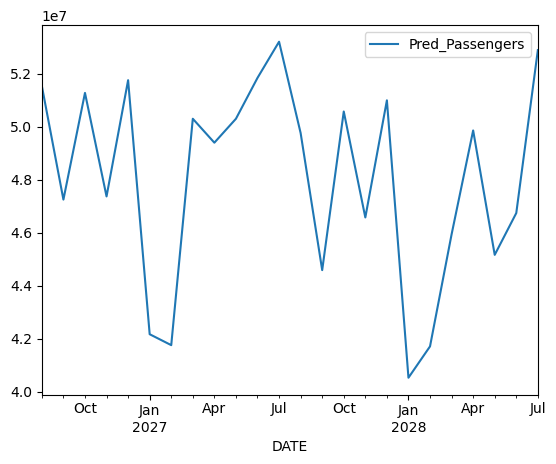

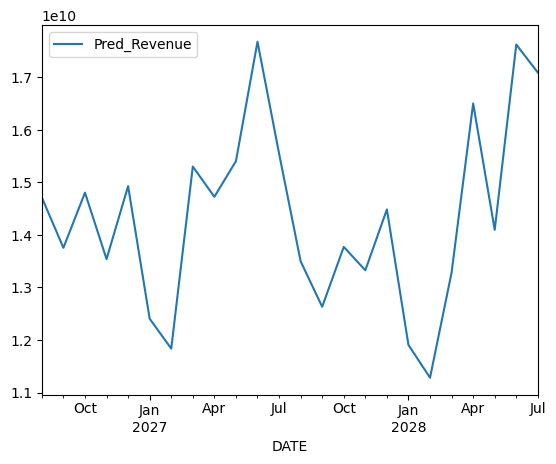

In [27]:
plot_df = forecast_out.copy()

plot_df['DATE'] = pd.to_datetime(dict(year=plot_df["DEP_YEAR"], month=plot_df["DEP_MONTH"], day=1))
plot_df_agg = plot_df.groupby('DATE').sum()
plot_df_agg.plot(kind='line',y='Pred_Passengers')
plot_df_agg.plot(kind='line',y='Pred_Revenue')

In [19]:

forecast_out.to_csv("./data/made/AA_forecast.csv", index=False)

print(forecast_out.head(10).to_string(index=False))

  ROUTE ORG_AIRPRT DES_AIRPRT  DEP_YEAR  DEP_MONTH  Pred_Passengers  Pred_Revenue
ABQ-ALB        ABQ        ALB      2026          8           457.00    114,921.52
ABQ-ALB        ABQ        ALB      2026          9           403.80    107,394.28
ABQ-ALB        ABQ        ALB      2026         10           487.70    107,109.46
ABQ-ALB        ABQ        ALB      2026         11           363.30     82,823.24
ABQ-ALB        ABQ        ALB      2026         12           431.20    104,320.83
ABQ-ALB        ABQ        ALB      2027          1           284.10     60,318.58
ABQ-ALB        ABQ        ALB      2027          2           308.80     77,227.75
ABQ-ALB        ABQ        ALB      2027          3           379.90    101,617.64
ABQ-ALB        ABQ        ALB      2027          4           393.40    104,480.99
ABQ-ALB        ABQ        ALB      2027          5           498.50    122,661.65


In [28]:


# 1. Save Passenger models (XGBoost native JSON + RF uncompressed joblib)
pax_results["xgb_model"].save_model("xgb_pax_tuned.json")
joblib.dump(pax_results["rf_model"], "rf_pax_tuned.joblib", compress=0)

# 2. Save Revenue models (XGBoost native JSON + RF uncompressed joblib)
rev_results["xgb_model"].save_model("xgb_rev_tuned.json")
joblib.dump(rev_results["rf_model"], "rf_rev_tuned.joblib", compress=0)

# 3. Save all winning hyperparameters, ensemble weights, metrics, and feature lists as JSON
model_registry = {
    "feature_cols": feature_cols,
    "rev_feature_cols": rev_feature_cols,
    "cat_cols": cat_cols,
    "num_cols": num_cols,
    "rev_num_cols": rev_num_cols,
    "Passengers": {
        "best_xgb_weight": float(pax_results["best_xgb_weight"]),
        "xgb_params": pax_results["xgb_params"],
        "rf_params": pax_results["rf_params"],
        "val_metrics": pax_results["val_metrics"],
    },
    "Revenue": {
        "best_xgb_weight": float(rev_results["best_xgb_weight"]),
        "xgb_params": rev_results["xgb_params"],
        "rf_params": rev_results["rf_params"],
        "val_metrics": rev_results["val_metrics"],
    },
}

with open("tuned_ensemble_registry.json", "w", encoding="utf-8") as f:
    json.dump(model_registry, f, indent=2)

print("All 4 tuned models + hyperparameters saved cleanly!")


All 4 tuned models + hyperparameters saved cleanly!


In [32]:
pax_results

{'xgb_model': XGBRegressor(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.03, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=9,
              max_leaves=None, min_child_weight=5, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=700,
              n_jobs=-1, num_parallel_tree=None, ...),
 'rf_model': Pipeline(steps=[('prep',
                  ColumnTransformer(transformers=[('num',
                                                   SimpleImputer(fill_value=-999.0,
                                                        

In [1]:
rev_results['val_metrics']

NameError: name 'rev_results' is not defined